In [2]:
from pathlib import Path
home = Path.home()
shared = Path('/home/shared/owner')
root = shared/'CoP_files/input/CF6_IORSIM_AH/CF6_IORSIM'

In [3]:
from numpy import pi, diff, cumsum, array
from ior2ecl import IORSim_output
from IORlib.ECL import UNSMRY_file

stb2m3 = 1.0 / 6.289811                # 0.158987294928 m3
stb_day2cm3_hour = stb2m3 * 1e6 / 24   # 1 m3 = 1e6 cm3

dia = 3.8  # cm
L = 22.4   # cm
porosity = 0.4
vol = L * pi * (0.5*dia)**2  # cm^3
porvol = porosity * vol      # cm^3

smry = UNSMRY_file(root)
ix = smry.welldata(wells=('Prod_Com',), keys=('WWPR','WOPR'), named=True, as_array=True)
ior_no = IORSim_output(root).welldata('Prod_Com', path='ior_nocorr')
ior = IORSim_output(root).welldata('Prod_Com', path='ior_corr')

#print(len(ix.days), len(ior.days))
# Convert to porevolume
watrate = ix.WWPR.Prod_Com * stb_day2cm3_hour
oilrate = ix.WOPR.Prod_Com * stb_day2cm3_hour
# Skip first ix data to be in sync with ior data, i.e. ix.days[1] == ior.days[0]
watrate = watrate[1:]
oilrate = oilrate[1:]
totrate = watrate + oilrate
# For some reason ior step 129 is out of sync with the ix steps
#list(zip(range(1000), ix.days[1:], ior.days))
dt = diff(ior.days)*24
#PV = cumsum(rate[1:]*dt)/porvol
PV = cumsum(totrate*dt)/porvol

In [ ]:
class welldata:
    stb2m3 = 1.0 / 6.289811        # 0.158987294928 m3
   
    def __init__(self) -> None:
        self.measures = ()
        self.wells = ()
        self.data = ()

    def as_numpy(self):
        pass

    def as_tuple(self):
        pass


In [6]:
from pandas import ExcelFile, read_excel
xls = ExcelFile(Path.home()/'github/IORSim/cases/CF6_IORSIM_AH/CF6_ions_v2.xlsx')
ions = read_excel(xls, sheet_name='ions')
ions_comb = read_excel(xls, sheet_name='ions-combined')
ions_ior = read_excel(xls, sheet_name='ions-IORSim')

NameError: name 'ions' is not defined

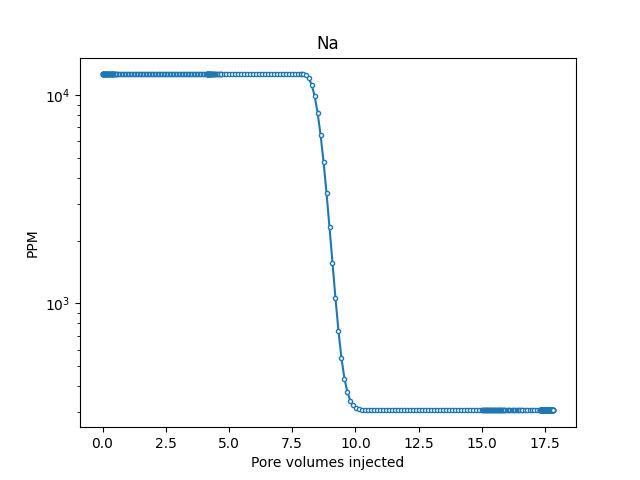

In [4]:
import matplotlib.pyplot as pl
from IORlib.utils import molL2ppm
%matplotlib widget
pl.close('all')
species = ['Na', 'K', 'Ca', 'Mg', 'Cl', 'SO4']
#for sp, c in zip(ior_noior.conc.items():
for specie in species:
    SPECIE = specie.upper()
    pl.figure()
    pl.title(specie)
    pl.xlabel('Pore volumes injected')
    pl.ylabel('PPM')
    p1, = pl.semilogy(PV, molL2ppm(specie) * array(ior.conc[SPECIE][1:]), '-o', mfc='w', ms=3, label='IORSim')
    p2, = pl.semilogy(ions['PV'], ions[specie], 'o', alpha=0.75, label='Data')
    #p21, = pl.semilogy(ions_comb['PV'][:], molL2ppm(specie)*ions_ior[SPECIE][:-5], 'o', alpha=0.75, label='Old sim')
    ax2 = pl.twinx()
    p3, = ax2.plot(PV, watrate, 'g-', alpha=0.4, label='WWPR')
    p4, = ax2.plot(PV, oilrate, 'r-', alpha=0.4, label='WOPR')
    ax2.set_ylabel(r'$\mathrm{cm}^3$/hour')
    pl.legend(handles=[p1, p2, p3, p4], bbox_to_anchor=(.22, 0.5), borderaxespad=0, ncols=1)
    savename = root.with_name(f'plot_{SPECIE}.pdf')
    pl.savefig(savename, dpi=300)
    print(savename)
    #pl.semilogy(PV, molL2ppm(specie) * array(ior_no.conc[SPECIE][1:]), '-o', mfc='None', ms=4, label='No corr')


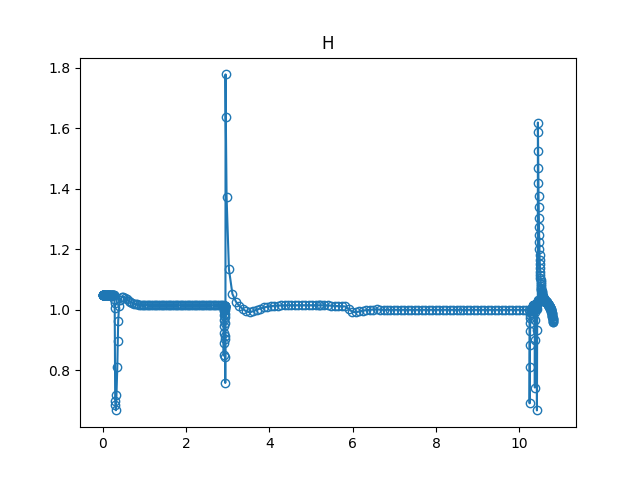

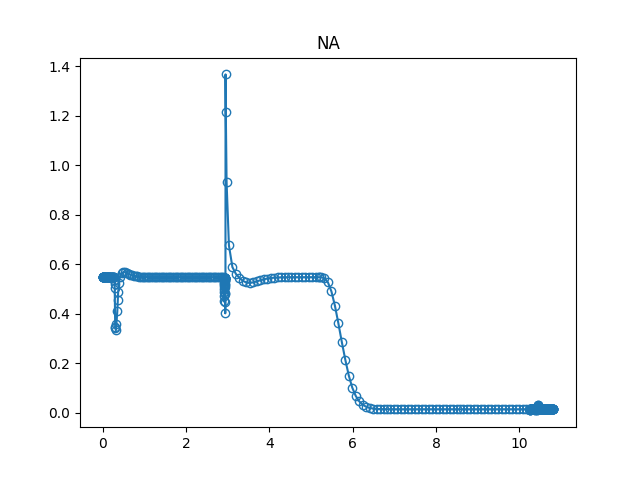

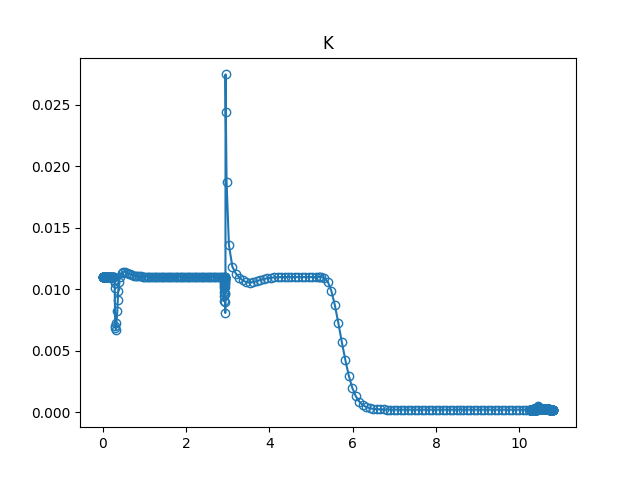

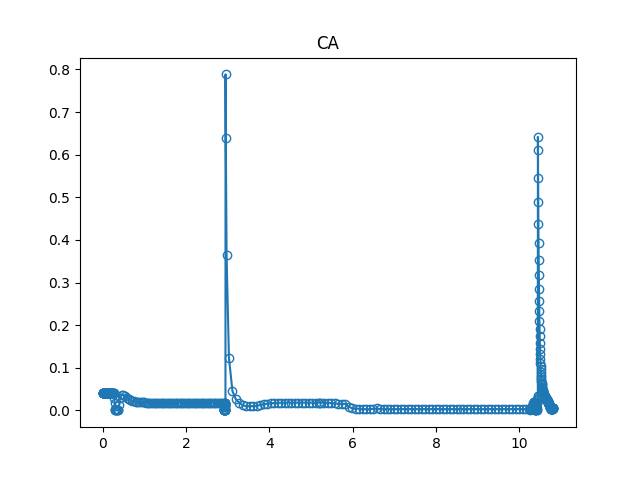

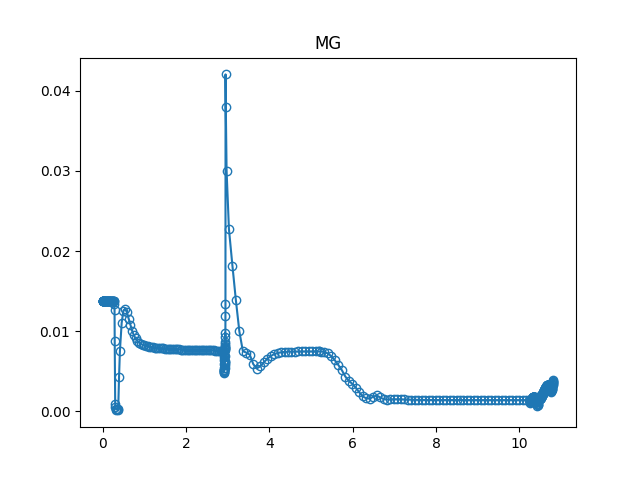

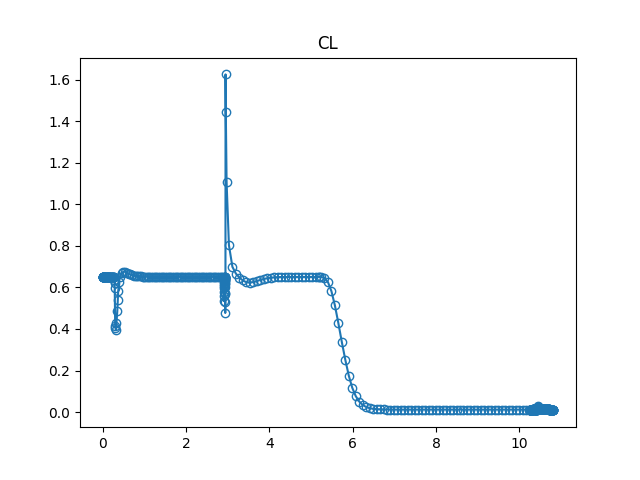

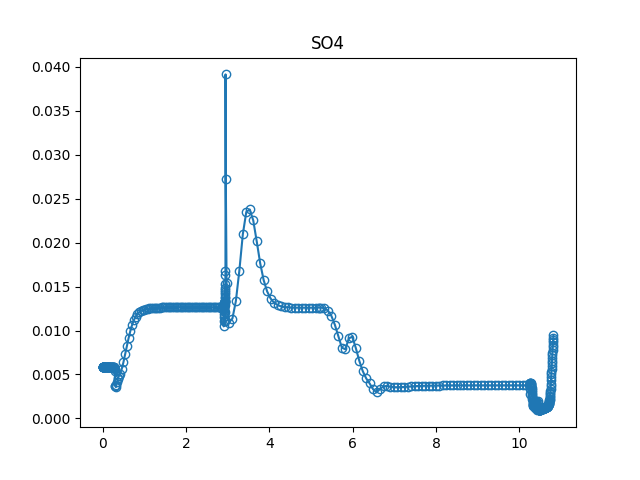

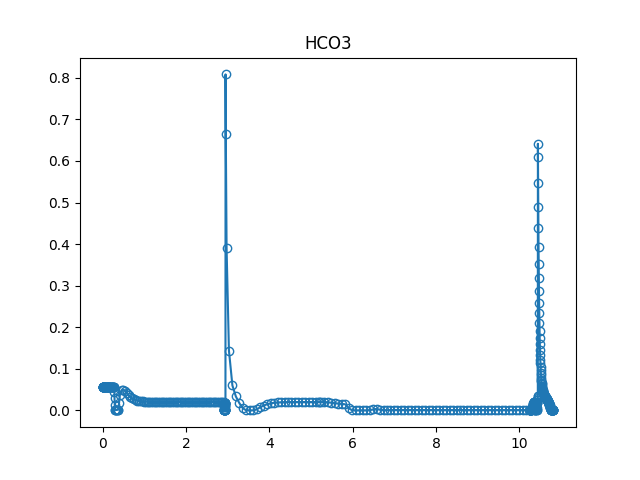

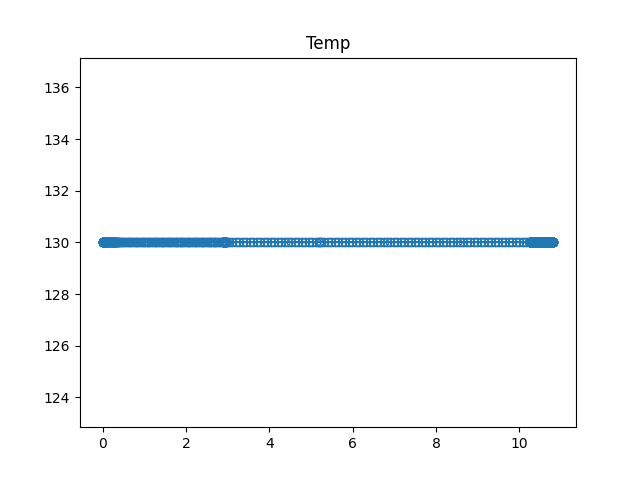

In [5]:
import matplotlib.pyplot as pl
from ior2ecl import IORSim_output
data = IORSim_output(root).welldata('Prod_Com')
#pl.plot(data.days, data.conc['CL'], '-o', mfc='None')
pl.close('all')
for specie, conc in data.conc.items():
    pl.figure()
    pl.title(specie)
    pl.plot(data.days, conc, '-o', mfc='None')

In [ ]:
from IORlib.ECL import UNSMRY_file
smry = UNSMRY_file(root)
pl.close('all')
smry.plot(keys=('WOPR', 'WWPR','WWIR'), args={'linestyle':'-', 'ms':5, 'mfc':'None'})

In [ ]:
from IORlib.ECL import File
from itertools import islice
from struct import unpack
from pathlib import Path

home = Path.home()
shared = Path('/home/shared/owner')
root = shared/'CoP_files/input/CF6_IORSIM_AH/CF6_IORSIM'
#gsg = root.parent/'CF6_IORSIM_CONNATE_WATER_SATURATION.GSG'
#gsg = root.parent/'CF6_IORSIM_PERM_I.GSG'
gsg = root.parent/'CF6_IORSIM_POROSITY.GSG'
#gsg = root.parent/'CF6_IORSIM_PRESSURE.GSG'
#gsg = root.parent/'CF6_IORSIM_CONNATE_WATER_SATURATION_KR.GSG'
with open(gsg, 'rb') as file:
    next(islice(file, 1, None))
    
    line = next(file)[4:]
    print(list(bytearray(line[:16])))
    print(line[16:27])
    print(list(bytearray(line[27:31])))
    print(line[31:39])
    print(list(bytearray(line[39:59])))
    pos = 59
    prop = unpack('<4s3i', line[pos:pos+16])
    pos += 16
    print(prop)
    key = prop[-1]
    print(line[pos:pos+key])
    pos += key
    print(unpack('<20f', line[pos+16:-1]))
    
    line = next(file)
    pos = 3
    prop = unpack('<10si4s2i4s4s2i', line[pos:pos+42])
    pos += 42
    print(prop)
    key = prop[-1]
    prop = unpack(f'<{key}s4s3i', line[pos:pos+key+16])
    pos += key+16
    print(prop)
    key = prop[-1]
    prop = unpack(f'<{key}s3i', line[pos:pos+key+12])
    pos += key+12
    print(prop)
    key = prop[-1]
    prop = unpack(f'<{key}s3i', line[pos:pos+key+12])
    print(prop)

    line = next(file)
    pos = 3
    print(list(bytearray(line[:pos])))
    prop = unpack('<10s5i', line[pos:pos+30])
    print(prop)


In [3]:
from itertools import islice

from more_itertools import flatten
from IORlib.ECL import RFT_file, File, IX_input, UNSMRY_file
from IORlib.utils import take
from numpy import array, max as npmax, diff as npdiff
from pprint import PrettyPrinter

# def diff(tubsum, total):
#     diff = tubsum[:-1] - tubsum[1:]
#     if tubsum[0] > 0:
#         # Producer
#         return array((*diff, tubsum[-1]))
#     else:
#         # Injector
#         #o, w, g = (0,1,2)
#         #surf = array(wellplt[:3])
#         #frac = surf/sum(surf)
#         #res_rate = wellplt[1]*frac
#         return array((total - tubsum[0], *diff))

def convert(data):
    keys = ('CONOTUB', 'CONWTUB', 'CONGTUB')
    idx = data['CONNXT']
    #if max(idx) >= len(data['CONOTUB']):
    try:
        # diff = {key:data[key][idx][:-1]-data[key][idx][1:] for key in keys}
        diff = {key:data[key][:-1]-data[key][1:] for key in keys}
    except IndexError:
        return False
    #diff = {key:data[key][:-1]-data[key][1:] for key in keys}
    if data['CONWTUB'][0] > 0:
        typ = 'Producer'
        rates = ((k, array((*v, data[k][-1]))) for k,v in diff.items())
    else:
        typ = 'Injector'
        #surf = array(data['WELLPLT'][:3])
        #frac = surf/sum(surf)
        #res_rate = wellplt[1]*frac
        rates = ((k, array((data['WELLPLT'][i] - data[k][0], *v))) for i,(k,v) in enumerate(diff.items()))
    conrat = ((k,v) for k,v in data.items() if 'RAT' in k)
    header = (('date', data['DATE']), ('well', data['WELLETC'][1]+' '+data['WELLETC'][6]), ('type', typ)) #, ('CONNXT', data['CONNXT']))
    return dict( header + tuple(flatten(zip(conrat, rates))))

def max_diff(data):
    for i, d in enumerate(data):
        if rates := convert(d):
            diff = (rates[f'{key}RAT'] - rates[f'{key}TUB'] for key in ('CONO', 'CONW', 'CONG'))
            yield i, list(map(npmax, diff)), rates, ('CONNXT', d['CONNXT']), ('CONWTUB', d['CONWTUB']) #, [d[f'CON{i}POS'] for i in ('I', 'J', 'K')] #d
        else:
            print(f"{i}: Skipped well {d['WELLETC'][1]} at {d['DATE']}: ")
            print(f"{d['CONNXT']}\nCONORAT:{d['CONORAT']}\nCONOTUB:{d['CONOTUB']}")

root = shared/'CoP_files/output/IORSIM_BASECASE_1971TO2022/IORSIM_BASECASE_1971TO2022'
#inp = IX_input(root)
#wells = dict(inp.wells())
#inj = [wel for wel,typ in wells.items() if 'WATER_INJ' in typ]
rft = RFT_file(root)
keys = ('DATE', 'WELLETC', 'WELLPLT', 'CONOTUB', 'CONORAT', 'CONWTUB', 'CONWRAT', 'CONGTUB', 'CONGRAT', 'CONNXT')
rftdata = (dict(zip(keys, (array(d) for d in bd))) for bd in rft.blockdata(*keys))
#convert(next(islice(rftdata, 7000, None)))
limit = 1
failed = (out for out in max_diff(rftdata) if out and any(o>limit for o in out[1]))
next(islice(failed, 2000, None))
#failed = next(out for out in max_diff(rftdata) if any(o>limit for o in out[1]))
#pp = PrettyPrinter(sort_dicts=False)
#pp.pprint(failed)

(13438,
 [0.0, 4936.39892578125, 2.1324988216248064e-12],
 {'date': array([   2,    7, 1993]),
  'well': 'K25 STANDARD',
  'type': 'Injector',
  'CONORAT': array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0.]),
  'CONOTUB': array([-0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,
          0.,  0.,  0.,  0.,  0.,  0.,  0.]),
  'CONWRAT': array([-2438.74389648, -2497.65527344,     0.        ,     0.        ,
             0.        ,     0.        ,     0.        ,     0.        ,
             0.        ,   -62.24019241,  -967.81311035,   -32.15384674,
         -2107.13867188,   -83.40231323, -1180.85266113,     0.        ,
             0.        ,     0.        ,     0.        ,     0.        ]),
  'CONWTUB': array([-6872.34472656, -2497.65527344,     0.        ,     0.        ,
             0.        ,     0.        ,     0.        ,     0.        ,
             0.        ,  9307.75976562,  -967.81347656,   -32.15332031,
       

In [ ]:
well = set()
for connxt, welletc in rft.blockdata('CONNXT', 'WELLETC'):
    if max(npdiff(array(connxt))) > 1:
        w = welletc[1]
        if w not in well:
            print(f'{w} {welletc[6]}: {connxt}')
        well.add(w)


In [ ]:
from datetime import datetime
from IORlib.ECL import UNRST_file

unrst = UNRST_file(root)
start = next(i for i,date in enumerate(unrst.dates()) if date >= datetime(1982, 10, 1))
cells = next(unrst.icellarray('FLRWATI+', 'FLRWATJ+', 'FLRWATK+', start=start))
[cells.flrwati[i,j,k]+cells.flrwatj[i,j,k]+cells.flrwatj[i,j,k] for i,j,k in zip(*failed[-1])]


In [ ]:
from datetime import datetime

smry = UNSMRY_file(root)
smrydata = smry.welldata(wells=('B21',), named=True)
list((d,r) for d,r in zip(smrydata.dates, smrydata.WWPR.B21) if d>=datetime(1982, 10, 1) )


In [ ]:
from IORlib.ECL import IX_input
inp = IX_input(root)
inp.findall('DATE "2-Jan')


In [ ]:
def well(rate, well='Inj_Comp'):
    return f'Well "{well}" {{\n    Constraints=[Constraint({rate} WATER_INJECTION_RATE)]\n}}'

def date(start, sec):
    return f'DATE "{start}:{sec:02d}"'
    
def soft_rate_inc(Q0, Q1, steps=10):
    dq = (Q1[1]-Q0[1])/steps
    rates = (Q0[1]+(i+1)*dq for i in range(steps))
    start = Q1[0]
    print(f'# Increase rate from {Q0[1]} to {Q1[1]} in {steps} steps of size {dq}')
    for i,rate in enumerate(rates):
        print(well(rate) + '\n' + date(start, i+1))

Q0 = ('1-Jan-2000 00:00' , 0.00090573269926)
Q1 = ('3-Jan-2000 21:42' , 0.0045286634963)
Q2 = ('3-Jan-2000 22:18' , 0.0090573269926)
Q3 = ('3-Jan-2000 22:36' , 0.0181146539852)
Q4 = ('3-Jan-2000 22:45' , Q0[1])
Q5 = ('11-Jan-2000 05:45', Q1[1])
Q6 = ('11-Jan-2000 08:45', Q2[1])
Q7 = ('11-Jan-2000 09:57', Q3[1])
Q8 = ('11-Jan-2000 10:33', Q0[1])

print('# JLV ----------------------------------------')
soft_rate_inc(Q3, Q4)
print('# JLV ----------------------------------------')


from ior2ecl import IORSim_output, IORSim_input
import matplotlib.pyplot as pl
%matplotlib widget
iorinp =IORSim_input(root)
#iorinp.wells()
out = IORSim_output(root)
ior_data = out.data('Prod_Com')
#ior_data.conc['CA']
pl.close('all')
fig, ax = pl.subplots(ncols=1, figsize=(10, 3.5))
#ax.semilogy(ior_data.days, ior_data.conc['CL'])
ax.plot(ior_data.days, ior_data.conc['CL'], '-o', mfc='None')


In [ ]:
data = smry.welldata(keys=('WWPR',), named=True)
#data.WWPR.Prod_Com
[f'{str(d).split(".")[0]}, {r:.8e}, {c}' for d,r,c in (zip(data.dates, data.WWPR.Prod_Com, ior_data.conc['CL']))]

In [ ]:
from IORlib.ECL import UNRST_file
unrst = UNRST_file(root)
next(unrst.section_blocks())
